# SmartTrip CDO: Static RAG for Travel Itineraries

| | |
|---|---|
| **Type** | Research project + poster (Department of Data Science) |
| **Domain** | Generative AI · Tourism · Retrieval-Augmented Generation |
| **Tools** | Python, pandas, Gemini 2.5 Flash API, regex, `to_markdown` |
| **Date** | October 2026 (dummy) |
| **Repository** | [RenzWoo/smart-trip-cdo (dummy link)](https://github.com/RenzWoo/smart-trip-cdo) |

:::{tip} TL;DR
A zero-cost, *static* RAG pipeline that turns a natural-language trip request into a day-by-day itinerary for Cagayan de Oro City. An LLM parses the request into JSON, **pandas retrieves matching places deterministically** from a hand-curated 47-place database, and the LLM writes the itinerary using *only* the retrieved rows. Tested on 10 traveller scenarios.
:::

<div class="stats-grid">
<div class="stat-card"><div class="stat-num">47</div><div class="stat-desc">manually curated places (POIs)</div></div>
<div class="stat-card"><div class="stat-num">3</div><div class="stat-desc">pipeline stages: parse → filter → generate</div></div>
<div class="stat-card"><div class="stat-num">10</div><div class="stat-desc">traveller test scenarios</div></div>
<div class="stat-card"><div class="stat-num">₱0</div><div class="stat-desc">infrastructure cost: no vector DB, no paid APIs</div></div>
</div>

## 1. Problem Statement

Commercial itinerary platforms depend on live data feeds and paid APIs, which is often too costly for
developing regions and small local governments. LLMs alone can write fluent itineraries, but they
**hallucinate places** and ignore logistics (jumping across the city in one day).

**Research question:** *Can a static, manually curated database plus prompt engineering generate grounded,
logistically coherent itineraries?*

**Objectives**

- Ground every recommendation in a verified local database (no invented places).
- Group each day's stops by **location cluster** to reduce travel time.
- Respect the traveller's budget tier, interests, group type, and trip length.
- Evaluate the system with measurable metrics instead of eyeballing the output.

The work aligns with UN SDGs 8 (decent work and economic growth), 9 (industry, innovation, infrastructure)
and 11 (sustainable cities and communities).

## 2. Data & Storage

The "database" is intentionally simple: **one curated CSV loaded into a pandas DataFrame**. There is no
database server, vector store, or external API at inference time, which is what makes the system zero-cost.

| Item | Details |
|---|---|
| **POI table** | 47 rows, curated by hand in a spreadsheet and exported to CSV |
| **Scenario table** | 10 test cases (`ID`, `Scenario_Name`, `Duration`, `Group_Type`, `Interests`, `Budget`) |
| **Storage in memory** | `pandas.DataFrame` for POIs; a Python `dict` keyed by scenario ID holds each run (itinerary text, filtered POIs, parsed preferences) |
| **Exports** | Evaluation summary saved to `baseline_comparison.csv` |

**POI schema**

| Column | Type | Notes |
|---|---|---|
| `name` | text | Unique place name (used as the grounding key) |
| `type` | categorical | Attraction, Food Market, Shopping, Museum, Restaurant, Accommodation, Landmark |
| `category` | multi-valued text | Pipe-delimited tags, e.g. `Adventure\|Nature\|WaterSports` |
| `location_cluster` | categorical | Area label such as Cugman, Downtown, Uptown, River Area, Malasag, Opol, Tambo |
| `avg_time_hours` | numeric | Typical time spent |
| `price_range` | ordinal | `budget` < `mid-range` < `premium` |
| `minimum_price_estimate(Php)`, `maximum_price_estimate(Php)` | numeric (stored as text) | Values such as `"2,000"` |
| `description`, `best_for` | text | `best_for` is pipe-delimited (Families, Shoppers, Naturelovers, ...) |
| `rating` | numeric | 1–5 scale |

## 3. Preprocessing & Data Engineering

| Step | What was done | Why |
|---|---|---|
| **Structured extraction** | Gemini turns free text into JSON: `duration_days`, `group_type`, `interests`, `budget_level`. Markdown fences are stripped and the JSON is parsed with error handling. | Converts messy user language into machine-usable filters |
| **Budget hierarchy** | `budget` ⊂ `mid-range` ⊂ `premium`: a mid-range traveller can also see budget places | Avoids empty results when cheaper options fit |
| **Multi-value matching** | Pipe-delimited `category` and `best_for` are matched with case-insensitive regex (`str.contains`, OR-joined interests) | Handles multi-label tags without a join table |
| **Numeric cleaning** | Price strings with thousands separators (`"2,000"`) are stripped of commas and cast to `float` before averaging | Needed for budget calculations |
| **Deterministic ordering** | Sorted by `location_cluster`, `price_range`, then `rating` (descending) | Keeps same-area places adjacent for the LLM |
| **Cluster statistics** | `value_counts()` over `location_cluster` finds the *dominant cluster*, and this summary is injected into the prompt | Steers the LLM to reuse a cluster across days |
| **Context serialization** | Filtered rows are rendered with `DataFrame.to_markdown()` and inserted into the prompt | This is the "retrieved context" in RAG |
| **Empty-result guard** | If zero places match, generation is skipped and the case is logged as a *graceful failure* | Prevents the LLM from inventing content |

## 4. Method: Three-Stage Pipeline

```text
 User query ──▶ [1] Preference extraction ──▶ [2] Deterministic filtering ──▶ [3] Grounded generation ──▶ Itinerary
 (free text)     Gemini → structured JSON      pandas on the curated CSV        Gemini, filtered rows only     (Day 1…N)
```

1. **Preference extraction (LLM):** natural language → JSON with duration, group type, interests, budget tier.
2. **Deterministic filtering (pandas):** budget hierarchy + interest and group-type matching. This retrieval
   step is fully reproducible and auditable; it is the "static RAG" part.
3. **Grounded generation (LLM):** the prompt contains only the filtered POIs plus rules: *one primary
   location cluster per day*, 6–10 hours per day, a ±20% daily budget band, exact place names, and a strict
   output format (`### Day N` sections with cost and time per stop).

The three tiers used for daily budgets are ₱800 (budget), ₱2,000 (mid-range), and ₱2,500 (premium).

### Evaluation metrics

| Metric | Definition | Target |
|---|---|---|
| **Hallucination Rate (HR)** | % of mentioned places that are not in the filtered POI set | 0% |
| **Clustering Efficiency (CE)** | % of same-day place pairs that share a location cluster | ≥ 80% |
| **Budget Variance (BV)** | % deviation of average daily cost from the tier's target budget | ≤ 10% |
| **Narrative Quality (NQ)** | Rule-based 1–5 score (day structure, logistics notes, costs, descriptions, personalisation) | 4–5 |

## 5. Results

Two runs are reported: the final numbers shown on the project poster and the latest saved notebook run.
LLM generation is non-deterministic, so scores move between runs (see next steps).

| Metric | Target | Poster (final run) | Notebook (saved run, 9 successful scenarios) |
|---|---|---|---|
| Hallucination Rate | 0% | **0.0%** | 0.0% |
| Clustering Efficiency | ≥ 80% | **76.32%** | 61.90% |
| Budget Variance | ≤ 10% | **51%** | 54.50% |
| Narrative Quality | 4–5 / 5 | **4.07** | 4.06 |

Scenario S9 (*Group Celebration*: nightlife, activities) matched **0 places**, and the pipeline correctly
refused to generate rather than making something up.

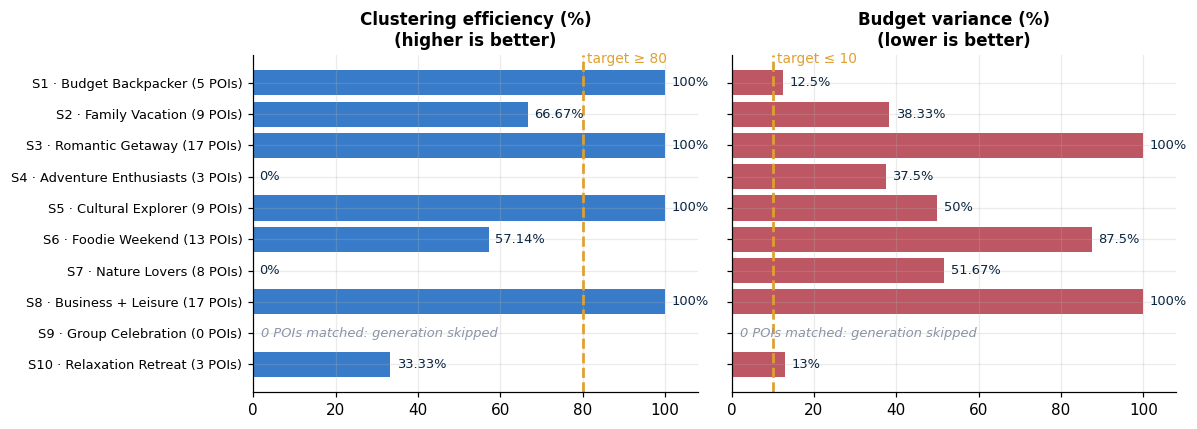

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

NAVY, BLUE, SKY, GOLD, RED, GREY = "#0A2540", "#1565C0", "#4FC3F7", "#E0A030", "#B23A48", "#8A94A6"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10, "font.size": 10,
})

# Per-scenario results transcribed from the saved notebook run (evaluation table)
res = pd.DataFrame({
    "scenario": ["S1","S2","S3","S4","S5","S6","S7","S8","S9","S10"],
    "name": ["Budget Backpacker","Family Vacation","Romantic Getaway","Adventure Enthusiasts",
             "Cultural Explorer","Foodie Weekend","Nature Lovers","Business + Leisure",
             "Group Celebration","Relaxation Retreat"],
    "pois": [5, 9, 17, 3, 9, 13, 8, 17, 0, 3],
    "CE":   [100, 66.67, 100, 0, 100, 57.14, 0, 100, np.nan, 33.33],
    "BV":   [12.5, 38.33, 100, 37.5, 50, 87.5, 51.67, 100, np.nan, 13],
})

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
y = np.arange(len(res))[::-1]
for ax, col, target, color, title, better in [
    (axes[0], "CE", 80, BLUE, "Clustering efficiency (%)", "higher is better"),
    (axes[1], "BV", 10, RED, "Budget variance (%)", "lower is better"),
]:
    ax.barh(y, res[col].fillna(0), color=color, alpha=0.85)
    for yi, v in zip(y, res[col]):
        if not np.isnan(v):
            ax.text(min(v, 100) + 1.5 if v > 0 else 1.5, yi, f"{v:g}%", va="center", fontsize=8.5, color=NAVY)
    ax.axvline(target, color=GOLD, ls="--", lw=1.8)
    ax.text(target + 1, len(res) - 0.45, f"target {'≥' if col=='CE' else '≤'} {target}", color=GOLD, fontsize=9, va="bottom")
    ax.set_title(f"{title}\n({better})", fontsize=11)
    ax.set_xlim(0, 108)
for i, r in res.iterrows():
    if np.isnan(r["CE"]):
        for ax in axes:
            ax.text(2, y[i], "0 POIs matched: generation skipped", va="center", fontsize=8.5, color=GREY, style="italic")
axes[0].set_yticks(y)
axes[0].set_yticklabels([f"{s} · {n} ({p} POIs)" for s, n, p in zip(res.scenario, res.name, res.pois)], fontsize=8.5)
plt.tight_layout()
plt.show()

### Reading the results

- **No invented place names were flagged** in any scenario, and the empty-result guard behaved as designed.
- **Clustering depends on database density.** Scenarios that matched only 3 places (S4, S10) or many
  one-place clusters (S7) score low. The retrieval step can only cluster what the database contains.
- **Budget variance is high for premium scenarios (S3, S8).** The price estimates in the 47-place table rarely
  reach the ₱2,500 daily target, which points to a calibration gap between the data and the budget tiers, not
  only an LLM issue.
- **Narrative quality is consistently around 4/5**, but it is a rule-based structural score, not a human rating.

```{figure} ../images/smart-trip-poster.jpg
:width: 85%
:align: center
:alt: SmartTrip CDO research poster

Project poster: abstract, three-stage architecture, evaluation results, and conclusion.
```

## 6. Data Science Concepts Demonstrated

| Concept | Where it appears |
|---|---|
| **Retrieval-Augmented Generation (RAG)** | Deterministic retrieval from a curated table, then generation restricted to retrieved rows |
| **Grounding & hallucination control** | Exact-name rules, filtered context only, empty-result guard |
| **Prompt engineering** | Cluster-aware strategy text, output templates, budget bands, mandatory rules |
| **LLM structured output** | Query → JSON with validation and error handling |
| **Data curation & schema design** | Hand-built POI table with ordinal, categorical, and multi-valued fields |
| **Feature/text matching** | Regex over pipe-delimited tags; budget hierarchy as an ordinal filter |
| **Evaluation design** | Four custom metrics with explicit targets and a 10-scenario test set |
| **Reproducibility trade-offs** | Deterministic retrieval vs. non-deterministic generation |

## 7. Limitations & Next Steps

- **Small hand-built database.** 47 places leave coverage gaps (S9 returned nothing). Next: grow the table and
  add embedding-based retrieval so "nightlife" can match "bars" and "live music".
- **Stricter hallucination check.** HR currently searches the text for known place names from the filtered
  set, so it cannot detect a *made-up* name. Next: request JSON output and validate every listed place against
  the database, or extract all named places from the text and compare.
- **Metric refinement.** CE and BV rely on name matching in free text, and NQ is a heuristic. Next: structured
  output for exact parsing, plus human ratings or a rubric-based LLM judge for narrative quality.
- **Run-to-run variance.** The poster and notebook CE differ (76% vs. 62%). Next: fix the temperature, repeat
  each scenario several times, and report mean ± SD.
- **Move budget logic out of the prompt.** Use a deterministic selection step (greedy/knapsack under budget and
  cluster constraints) before the LLM writes the narrative.
- **Travel time, not just cluster labels.** Add a distance/time matrix between clusters.
- **User study.** Validate itineraries with real travellers or local tourism officers.